# Building a DDPM from Near-Scratch on CIFAR-10
**Domain:** Computer Vision, Generative Modeling | **Framework:** PyTorch | **Platform:** local Mac (Apple Silicon GPU via MPS)

**What this notebook does:** builds every core part of a Denoising Diffusion Probabilistic Model by hand (noise schedules, forward process, time-conditioned U-Net with self-attention, training loop, DDPM and DDIM samplers) and compares it with AE, VAE and DCGAN baselines using FID and Inception Score.

## How to use this notebook
1. Run cells **top to bottom** in Jupyter or VS Code on your Mac.
2. Sections are numbered to match the 20-step workflow.
3. **Time-budgeted for a laptop.** Training stops after `TRAIN_MINUTES`, and a checkpoint is saved every epoch. If the kernel dies, re-run the setup cells and the training cell and it resumes. If you already have `cosine_attn_final.pt` from Colab, copy it into `diffusion_project/checkpoints/` and Step 13 is skipped.
4. **Reordering note:** training logs sample grids using the DDIM sampler, so the sampler *code* is defined in Step 11 (as 11b). Steps 14 and 15 *run and analyse* the samplers.
5. This notebook does not contain results. Every number comes from your own runs; the markdown cells say what to look for, not what you will get.

| Phase | Steps |
|---|---|
| Setup and data | 1-4 |
| Diffusion mechanics | 5-6 |
| Model building | 7-10 |
| Training | 11-13 |
| Sampling | 14-15 |
| Evaluation and comparison | 16-18 |
| Extensions and wrap-up | 19-20 |

# Phase 1: Setup and data
## Step 1: Environment setup
**Objective:** confirm the GPU works, fix seeds, create local folders, and define all hyperparameters in one place.

**Why it matters:** a silent CPU fallback makes training 50-100x slower. Keeping hyperparameters in one cell means every experiment (ablations, baselines) uses the same settings.

In [ ]:
%pip install -r requirements.txt

In [1]:
import os, warnings
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"      # ops MPS lacks fall back to CPU instead of crashing
warnings.filterwarnings("ignore", message=".*device_type of 'cuda'.*")
import math, copy, time, random, shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
import torchvision.utils as vutils
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from PIL import Image
from IPython.display import display
import torch_fidelity



/Users/sundharamurali/Guvi_Projects/DDPM/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
# ---------- Device: CUDA > Apple GPU (MPS) > CPU ----------
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
AMP = device.type == "cuda"          # float16 autocast/GradScaler only used on NVIDIA GPUs; MPS runs float32
print("PyTorch:", torch.__version__, "| Device:", device)
if device.type == "cpu":
    print("WARNING: running on CPU will be far too slow for this project.")

# ---------- Seeds ----------
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# ---------- Local folders ----------
PROJECT_DIR = "./diffusion_project"
CKPT_DIR    = f"{PROJECT_DIR}/checkpoints"
SAMPLE_DIR  = f"{PROJECT_DIR}/samples"
DATA_DIR    = "./data"
FID_DIR     = "./fid_eval"
REAL_DIR    = f"{FID_DIR}/real_holdout"
for d in [CKPT_DIR, SAMPLE_DIR, DATA_DIR, FID_DIR]:
    os.makedirs(d, exist_ok=True)

# ---------- Hyperparameters (reduced for a ~3 hour laptop budget) ----------
IMG_SIZE        = 32
T               = 1000
BATCH_SIZE      = 128
EPOCHS          = 1000      # upper limit only; TRAIN_MINUTES normally stops training first
TRAIN_MINUTES   = 75        # wall-clock budget for the main model
LR              = 2e-4
WARMUP_STEPS    = 200
BASE_CH         = 32        # drop to 32 if one epoch takes more than ~4 minutes
EMA_DECAY       = 0.999     # faster EMA because we train for few steps
P_UNCOND        = 0.1
N_HOLDOUT       = 2500      # 5% of CIFAR-10 train, held out for FID/IS
N_FID           = 2500      # generated images per FID evaluation
BASELINE_EPOCHS = 10
print("Setup complete.")

PyTorch: 2.14.1 | Device: mps
Setup complete.


**Validation:** `Device: mps` (Apple GPU). If you see `cpu`, your PyTorch install is too old or not the macOS arm64 build.

**Professional insight:** note your GPU memory. If you hit `CUDA out of memory` later, lower `BATCH_SIZE` to 64 first, then `BASE_CH`. FID with only 2,500 samples is *biased upward* compared with the 50,000-sample FID in the paper, so we only compare models evaluated the same way and report the gap honestly in Step 20.

## Step 2: Load CIFAR-10
**Objective:** load CIFAR-10 and scale pixels to **[-1, 1]**.

**Why [-1, 1]?** The forward process adds zero-mean, unit-variance Gaussian noise. Data centred around 0 with a similar range makes the noise-vs-signal maths consistent. Scaling mismatches silently break training.

**Augmentation:** random horizontal flip only. Heavier augmentation makes the model learn a distorted distribution.

We create two views of the same data: one with flips (for training) and one without (for the held-out FID reference set).

In [3]:
norm = transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))      # [0,1] -> [-1,1]
train_tf = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.ToTensor(), norm])
plain_tf = transforms.Compose([transforms.ToTensor(), norm])

cifar_train_aug   = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=train_tf)
cifar_train_plain = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=plain_tf)

def to_01(x):
    # Convert [-1,1] images back to [0,1] for plotting/saving
    return (x.clamp(-1, 1) + 1) / 2

img, label = cifar_train_plain[0]
print("Dataset size :", len(cifar_train_plain))
print("Image shape  :", tuple(img.shape), "| label:", label, cifar_train_plain.classes[label])
print(f"Pixel range  : min={img.min():.2f}, max={img.max():.2f}")

100%|██████████| 170M/170M [49:28<00:00, 57.4kB/s]   


Dataset size : 50000
Image shape  : (3, 32, 32) | label: 6 frog
Pixel range  : min=-1.00, max=1.00


**Validation:** 50,000 images, shape `(3, 32, 32)`, pixel range within `[-1, 1]`.

## Step 3: Hold-out set and DataLoader
**Objective:** reserve 5% of the data (2,500 images) purely for FID/IS reference, and build the training DataLoader from the rest. (Same seed as the Colab version, so this hold-out is a subset of the Colab one: no leakage if you reuse a Colab checkpoint.)

**Why it matters (leakage):** if FID were computed against images the model trained on, a memorising model would look good. The hold-out images never touch training. We also save them as PNGs because `torch-fidelity` reads image folders.

In [4]:
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(cifar_train_plain), generator=g).tolist()
holdout_idx = perm[:N_HOLDOUT]
train_idx   = perm[N_HOLDOUT:]
assert len(set(holdout_idx) & set(train_idx)) == 0, "Leakage: overlap between train and hold-out!"

train_set   = Subset(cifar_train_aug, train_idx)       # flips, used for training
holdout_set = Subset(cifar_train_plain, holdout_idx)   # no augmentation, FID reference only

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=False, drop_last=True)

# Save hold-out images as PNGs for FID/IS computation
if os.path.exists(REAL_DIR):
    shutil.rmtree(REAL_DIR)
os.makedirs(REAL_DIR)
for i in tqdm(range(len(holdout_set)), desc="Saving hold-out PNGs"):
    vutils.save_image(to_01(holdout_set[i][0]), f"{REAL_DIR}/{i:05d}.png")

print("Train images   :", len(train_set), "| batches/epoch:", len(train_loader))
print("Hold-out images:", len(holdout_set), "| PNG files:", len(os.listdir(REAL_DIR)))
xb, yb = next(iter(train_loader))
print("Batch shape:", tuple(xb.shape), f"| range [{xb.min():.2f}, {xb.max():.2f}]")

Saving hold-out PNGs: 100%|██████████| 2500/2500 [00:00<00:00, 5954.68it/s]

Train images   : 47500 | batches/epoch: 371
Hold-out images: 2500 | PNG files: 2500
Batch shape: (128, 3, 32, 32) | range [-1.00, 1.00]


**Validation:** 47,500 train / 2,500 hold-out, 2,500 PNGs saved, batch shape `(128, 3, 32, 32)`.

**Insight:** `drop_last=True` keeps every batch the same size, which avoids edge cases in the training loop.

## Step 4: Exploratory Data Analysis
**Objective:** for generative modelling, EDA means understanding the *distribution the model must learn*: visual diversity, class balance, pixel statistics, and near-duplicates.

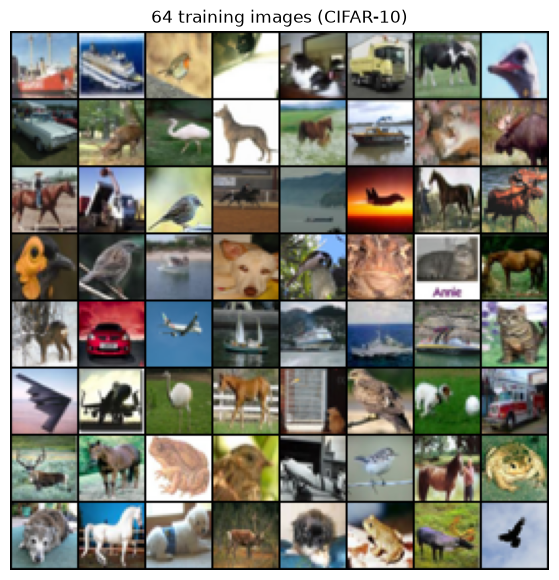

,class,count
0,airplane,4746
1,automobile,4763
2,bird,4752
3,cat,4760
4,deer,4744
5,dog,4756
6,frog,4735
7,horse,4739
8,ship,4740
9,truck,4765


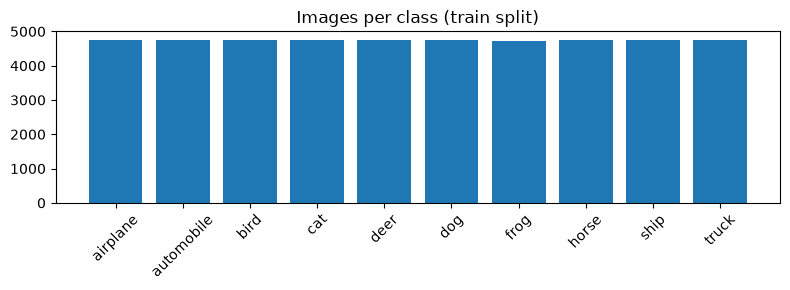

In [5]:
# Load 5,000 training images (no augmentation) as one tensor for EDA
eda_imgs = torch.stack([cifar_train_plain[i][0] for i in train_idx[:5000]])
eda_labels = np.array(cifar_train_plain.targets)[train_idx]
classes = cifar_train_plain.classes

# --- 4a. Sample grid ---
grid = vutils.make_grid(to_01(eda_imgs[:64]), nrow=8, padding=1)
plt.figure(figsize=(7, 7)); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
plt.title("64 training images (CIFAR-10)"); plt.show()

# --- 4b. Class balance (full training split) ---
counts = np.bincount(np.array(cifar_train_plain.targets)[train_idx], minlength=10)
display(pd.DataFrame({"class": classes, "count": counts}))
plt.figure(figsize=(8, 3)); plt.bar(classes, counts); plt.xticks(rotation=45)
plt.title("Images per class (train split)"); plt.tight_layout(); plt.show()

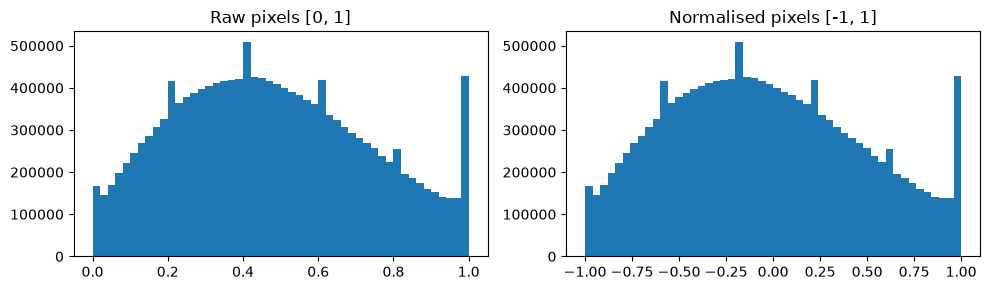

,channel,"mean_[0,1]","std_[0,1]","mean_[-1,1]","std_[-1,1]"
0,R,0.494,0.248,-0.011,0.496
1,G,0.486,0.244,-0.028,0.488
2,B,0.449,0.263,-0.101,0.526


Images sharing an identical 64-bit hash with another image: 25 of 5000
(These are duplicate *candidates* only; a coarse hash also produces false positives.)


In [6]:
# --- 4c. Pixel distribution before vs after normalisation ---
raw = to_01(eda_imgs)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(raw.flatten().numpy(), bins=50);      ax[0].set_title("Raw pixels [0, 1]")
ax[1].hist(eda_imgs.flatten().numpy(), bins=50); ax[1].set_title("Normalised pixels [-1, 1]")
plt.tight_layout(); plt.show()

# --- 4d. Channel-wise statistics ---
stats = pd.DataFrame({
    "channel": ["R", "G", "B"],
    "mean_[0,1]": raw.mean(dim=(0, 2, 3)).numpy().round(3),
    "std_[0,1]":  raw.std(dim=(0, 2, 3)).numpy().round(3),
    "mean_[-1,1]": eda_imgs.mean(dim=(0, 2, 3)).numpy().round(3),
    "std_[-1,1]":  eda_imgs.std(dim=(0, 2, 3)).numpy().round(3),
})
display(stats)

# --- 4e. Cheap near-duplicate check (average hash on 8x8 greyscale) ---
small = F.adaptive_avg_pool2d(eda_imgs.mean(dim=1, keepdim=True), 8).flatten(1)
bits = (small > small.mean(dim=1, keepdim=True)).numpy().astype(np.uint8)
hashes = [b.tobytes() for b in bits]
n_dup = len(hashes) - len(set(hashes))
print(f"Images sharing an identical 64-bit hash with another image: {n_dup} of {len(hashes)}")
print("(These are duplicate *candidates* only; a coarse hash also produces false positives.)")

**What to look for:**
- Classes should be roughly balanced (about 4,750 each in the train split, since the split is random).
- Normalised histogram spans about -1 to 1. Per-channel means near 0 after scaling (not exactly 0). Per-channel normalisation is *not* needed; the simple (x-0.5)/0.5 scaling is the diffusion standard.
- The duplicate count is only a coarse signal. A small number is expected; don't over-interpret it.

**Interview line:** "CIFAR-10 is balanced and small, so I only needed a light-touch pipeline: scaling to [-1, 1], flips only, and a leakage-free hold-out for FID."

# Phase 2: Diffusion mechanics
## Step 5: Noise schedules
**Objective:** implement **linear** and **cosine** beta schedules and precompute everything the training and sampling loops reuse.

**Key quantities** (t = 1..T):
- `beta_t`: noise variance added at step t
- `alpha_t = 1 - beta_t`
- `alpha_bar_t = product of alpha_1..alpha_t`: the fraction of original signal left after t steps

**Why cosine?** The linear schedule destroys information too fast near the end (the last steps are mostly wasted pure noise). The cosine schedule destroys it more gradually, which tends to give better samples.

We also precompute the **posterior** coefficients used by the DDPM sampler.

In [7]:
def linear_beta_schedule(num_steps, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start, beta_end, num_steps, dtype=torch.float64)

def cosine_beta_schedule(num_steps, s=0.008):
    # Nichol & Dhariwal (2021): define alpha_bar directly with a squared cosine, then derive betas
    steps = torch.arange(num_steps + 1, dtype=torch.float64)
    f = torch.cos(((steps / num_steps + s) / (1 + s)) * math.pi / 2) ** 2
    alpha_bar = f / f[0]
    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]
    return betas.clamp(max=0.999)           # avoid a singularity at the last step

def make_schedule(name, num_steps=T):
    betas = linear_beta_schedule(num_steps) if name == "linear" else cosine_beta_schedule(num_steps)
    alphas = 1.0 - betas
    alpha_bar = torch.cumprod(alphas, dim=0)
    alpha_bar_prev = torch.cat([torch.ones(1, dtype=torch.float64), alpha_bar[:-1]])
    s = {
        "betas": betas, "alphas": alphas, "alpha_bar": alpha_bar, "alpha_bar_prev": alpha_bar_prev,
        "sqrt_ab": alpha_bar.sqrt(), "sqrt_1m_ab": (1 - alpha_bar).sqrt(),
        # q(x_{t-1} | x_t, x_0) posterior used by DDPM ancestral sampling
        "post_var":   betas * (1 - alpha_bar_prev) / (1 - alpha_bar),
        "post_coef1": betas * alpha_bar_prev.sqrt() / (1 - alpha_bar),
        "post_coef2": (1 - alpha_bar_prev) * alphas.sqrt() / (1 - alpha_bar),
    }
    # computed in float64 for accuracy, cached on the GPU as float32 (they are reused every step)
    return {k: v.float().to(device) for k, v in s.items()}

def extract(a, t, x_shape):
    # Pick a[t] for each image in the batch and reshape to (B,1,1,1) so it broadcasts over images
    out = a.gather(0, t)
    return out.reshape(-1, *([1] * (len(x_shape) - 1)))

schedules = {"linear": make_schedule("linear"), "cosine": make_schedule("cosine")}

# Quick table of alpha_bar at selected timesteps (t is 0-indexed here)
idx = [0, 250, 500, 750, 999]
display(pd.DataFrame({
    "t": idx,
    "alpha_bar (linear)": [schedules["linear"]["alpha_bar"][i].item() for i in idx],
    "alpha_bar (cosine)": [schedules["cosine"]["alpha_bar"][i].item() for i in idx],
}))

,t,alpha_bar (linear),alpha_bar (cosine)
0,0,0.999900,9.999587e-01
1,250,0.521423,8.458880e-01
2,500,0.077797,4.922852e-01
3,750,0.003300,1.431786e-01
4,999,0.000040,2.428767e-09


**Validation:** `alpha_bar` starts near 1 and decays towards 0 for both schedules. The cosine schedule decays *more slowly early on* than linear (higher `alpha_bar` at t=250 and 500), and both end near 0.

**Common mistake:** an off-by-one between 0-indexed code (`t=0..T-1`) and the 1-indexed maths (`t=1..T`). Everywhere in this notebook `t` is a 0-indexed tensor index.

## Step 6: Forward (noising) process
**Objective:** implement the closed form that jumps straight to any timestep without looping:

`x_t = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * noise`

This is what makes training efficient: each training example picks a random `t` and jumps there in one step.

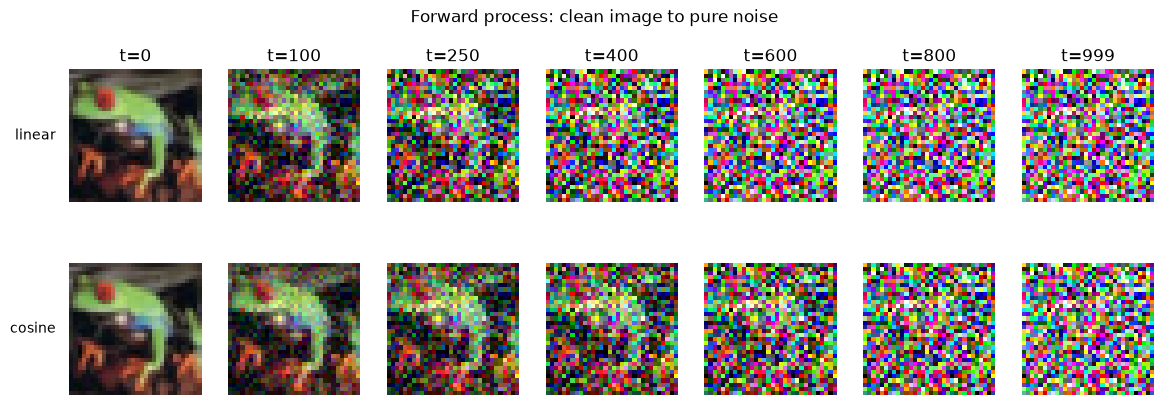

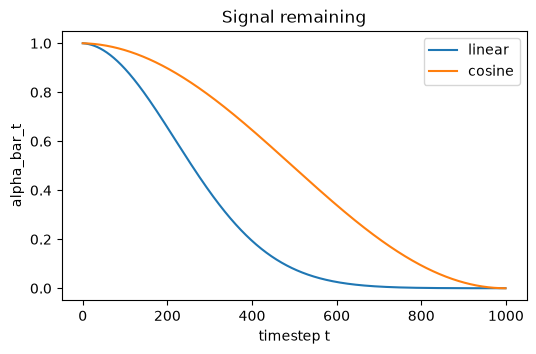

linear  final alpha_bar = 4.04e-05 | x_T mean=-0.01, std=1.01
cosine  final alpha_bar = 2.43e-09 | x_T mean=-0.00, std=1.01


In [8]:
def q_sample(x0, t, sched, noise=None):
    # Forward diffusion: noise a clean image x0 up to timestep t in one shot
    if noise is None:
        noise = torch.randn_like(x0)
    return extract(sched["sqrt_ab"], t, x0.shape) * x0 + extract(sched["sqrt_1m_ab"], t, x0.shape) * noise

# --- Visual sanity check: one image noised from t=0 to t=999 under both schedules ---
x0 = holdout_set[0][0].unsqueeze(0).to(device)
t_list = [0, 100, 250, 400, 600, 800, 999]
noise = torch.randn_like(x0)                      # same noise for both schedules (fair comparison)

fig, axes = plt.subplots(2, len(t_list), figsize=(2 * len(t_list), 4.6))
for row, name in enumerate(["linear", "cosine"]):
    for col, t_val in enumerate(t_list):
        t = torch.tensor([t_val], device=device)
        x_t = q_sample(x0, t, schedules[name], noise)
        axes[row, col].imshow(to_01(x_t[0]).permute(1, 2, 0).cpu()); axes[row, col].axis("off")
        if row == 0: axes[row, col].set_title(f"t={t_val}")
    axes[row, 0].text(-0.1, 0.5, name, transform=axes[row, 0].transAxes, ha="right", va="center")
plt.suptitle("Forward process: clean image to pure noise"); plt.show()

# --- alpha_bar curves ---
plt.figure(figsize=(6, 3.5))
for name in ["linear", "cosine"]:
    plt.plot(schedules[name]["alpha_bar"].cpu(), label=name)
plt.xlabel("timestep t"); plt.ylabel("alpha_bar_t"); plt.legend(); plt.title("Signal remaining"); plt.show()

# --- Numeric check at the final step: should look like pure N(0,1) noise ---
for name in ["linear", "cosine"]:
    x_T = q_sample(x0, torch.tensor([T - 1], device=device), schedules[name], noise)
    print(f"{name:7s} final alpha_bar = {schedules[name]['alpha_bar'][-1].item():.2e} | x_T mean={x_T.mean():.2f}, std={x_T.std():.2f}")

**Validation:** by t=999 the image should be unrecognisable in both rows, the final `alpha_bar` should be tiny, and `x_T` should have mean near 0 and std near 1. If the final image still shows structure, the schedule is wrong.

# Phase 3: Model building
We build the U-Net in four small pieces and test each one.

## Step 7: Sinusoidal timestep embedding
**Objective:** turn the integer timestep `t` into a rich vector, the same trick as positional encodings in Transformers. The network needs to know *how noisy* its input is, because denoising a barely-noisy image and a nearly-pure-noise image are very different jobs. A raw scalar `t` is a weak signal; sinusoids at many frequencies are far easier for the network to use.

Embedding shape: (1000, 64) (expected (1000, 64))


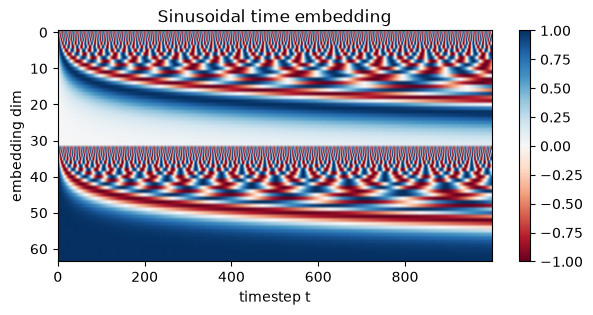

In [9]:
class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)  # geometric frequencies
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=-1)                                # (B, dim)

# Test: embed all 1000 timesteps and look at the pattern
emb = SinusoidalEmbedding(BASE_CH)(torch.arange(T))
print("Embedding shape:", tuple(emb.shape), "(expected (1000, 64))")
plt.figure(figsize=(7, 3)); plt.imshow(emb.T, aspect="auto", cmap="RdBu")
plt.xlabel("timestep t"); plt.ylabel("embedding dim"); plt.title("Sinusoidal time embedding"); plt.colorbar(); plt.show()

**Validation:** shape `(1000, 64)`; the heatmap shows smooth wave patterns, slow in some rows and fast in others. Every timestep gets a unique "fingerprint".

In the full U-Net this vector passes through a small MLP (`Linear > SiLU > Linear`) to produce the final time embedding.

## Step 8: Residual block with time conditioning
**Objective:** the main building block. Each block is `GroupNorm > SiLU > Conv`, twice, plus a skip connection, and the time embedding is **added** into the feature maps in the middle.

- **GroupNorm** (not BatchNorm): works with any batch size and is the standard for diffusion models.
- **SiLU:** smooth activation, the usual choice here.
- **Time injection:** a linear layer maps the time embedding to one value per channel, which is added to every pixel of that channel.

In [10]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(32, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_ch)          # time embedding -> one value per channel
        self.norm2 = nn.GroupNorm(32, out_ch)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(F.silu(t_emb))[:, :, None, None]   # inject time information
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)                                    # residual connection

# Test
blk = ResBlock(64, 128, time_dim=256)
out = blk(torch.randn(4, 64, 16, 16), torch.randn(4, 256))
print("ResBlock output:", tuple(out.shape), "(expected (4, 128, 16, 16))")

ResBlock output: (4, 128, 16, 16) (expected (4, 128, 16, 16))


**Validation:** channels change 64 to 128, spatial size unchanged. GroupNorm with 32 groups requires channel counts divisible by 32; that is why `BASE_CH` must be 32, 64, 128, etc.

## Step 9: Self-attention block
**Objective:** convolutions only see local neighbourhoods. Self-attention lets every pixel look at every other pixel, which helps global coherence (e.g. a horse's head and legs belonging together). Attention costs O(pixels^2), so we only use it at **16x16 and 8x8** (and the 4x4 bottleneck), not at 32x32.

In [11]:
class AttentionBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.norm = nn.GroupNorm(32, ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)     # one 1x1 conv produces queries, keys and values
        self.proj = nn.Conv2d(ch, ch, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        qkv = self.qkv(self.norm(x)).reshape(B, 3, C, H * W).permute(1, 0, 3, 2)   # (3, B, HW, C)
        q, k, v = qkv[0].contiguous(), qkv[1].contiguous(), qkv[2].contiguous()
        out = F.scaled_dot_product_attention(q, k, v)                              # (B, HW, C)
        out = out.permute(0, 2, 1).reshape(B, C, H, W)
        return x + self.proj(out)                                                  # residual

# Test
att = AttentionBlock(128)
out = att(torch.randn(4, 128, 16, 16))
print("Attention output:", tuple(out.shape), "(expected (4, 128, 16, 16))")

Attention output: (4, 128, 16, 16) (expected (4, 128, 16, 16))


**Validation:** shape is unchanged (attention is a drop-in layer). Note the residual `x + ...`, which makes the block safe to insert anywhere.

## Step 10: Full U-Net
**Objective:** assemble everything:
- **Encoder:** ResBlocks (+ attention at chosen resolutions), downsample with strided convs: 32 > 16 > 8 > 4
- **Bottleneck:** ResBlock, Attention, ResBlock
- **Decoder:** mirror image; each block receives the matching **skip connection** from the encoder (concatenated), upsample with nearest-neighbour + conv
- **Output:** conv back to 3 channels = predicted noise (same shape as input)

`use_attention=False` gives the no-attention variant for the ablation in Step 17. `num_classes` enables class conditioning for the optional Step 19.

In [12]:
class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, stride=2, padding=1)
    def forward(self, x):
        return self.conv(x)

class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))

def run_layers(layers, x, t_emb):
    # ResBlocks need the time embedding; all other layers take only x
    for layer in layers:
        x = layer(x, t_emb) if isinstance(layer, ResBlock) else layer(x)
    return x

class UNet(nn.Module):
    def __init__(self, in_ch=3, base_ch=64, ch_mult=(1, 2, 2, 2), num_res=2,
                 attn_res=(16, 8), img_size=32, dropout=0.1, use_attention=True, num_classes=None):
        super().__init__()
        time_dim = base_ch * 4
        self.num_classes = num_classes
        attn_res = attn_res if use_attention else ()

        self.time_mlp = nn.Sequential(SinusoidalEmbedding(base_ch), nn.Linear(base_ch, time_dim),
                                      nn.SiLU(), nn.Linear(time_dim, time_dim))
        # extra embedding row (index = num_classes) is the "no label" token for classifier-free guidance
        self.class_emb = nn.Embedding(num_classes + 1, time_dim) if num_classes else None
        self.init_conv = nn.Conv2d(in_ch, base_ch, 3, padding=1)

        # ---------- Encoder ----------
        self.down = nn.ModuleList()
        skip_chs = [base_ch]                      # channel counts of saved skip connections
        ch, res = base_ch, img_size
        for i, mult in enumerate(ch_mult):
            out_ch = base_ch * mult
            for _ in range(num_res):
                block = nn.ModuleList([ResBlock(ch, out_ch, time_dim, dropout)])
                if res in attn_res:
                    block.append(AttentionBlock(out_ch))
                self.down.append(block); ch = out_ch; skip_chs.append(ch)
            if i != len(ch_mult) - 1:
                self.down.append(nn.ModuleList([Downsample(ch)])); skip_chs.append(ch); res //= 2

        # ---------- Bottleneck ----------
        mid = [ResBlock(ch, ch, time_dim, dropout)]
        if use_attention:
            mid.append(AttentionBlock(ch))
        mid.append(ResBlock(ch, ch, time_dim, dropout))
        self.mid = nn.ModuleList(mid)

        # ---------- Decoder ----------
        self.up = nn.ModuleList()
        for i, mult in reversed(list(enumerate(ch_mult))):
            out_ch = base_ch * mult
            for j in range(num_res + 1):
                block = nn.ModuleList([ResBlock(ch + skip_chs.pop(), out_ch, time_dim, dropout)])
                ch = out_ch
                if res in attn_res:
                    block.append(AttentionBlock(ch))
                if i != 0 and j == num_res:
                    block.append(Upsample(ch)); res *= 2
                self.up.append(block)

        self.out = nn.Sequential(nn.GroupNorm(32, ch), nn.SiLU(), nn.Conv2d(ch, in_ch, 3, padding=1))

    def forward(self, x, t, y=None):
        t_emb = self.time_mlp(t)
        if self.class_emb is not None and y is not None:
            t_emb = t_emb + self.class_emb(y)            # class label is added to the time embedding
        x = self.init_conv(x)
        skips = [x]
        for block in self.down:
            x = run_layers(block, x, t_emb); skips.append(x)
        x = run_layers(self.mid, x, t_emb)
        for block in self.up:
            x = torch.cat([x, skips.pop()], dim=1)       # skip connection
            x = run_layers(block, x, t_emb)
        return self.out(x)

# ---------- Test with a dummy batch ----------
def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

for attn in [True, False]:
    net = UNet(base_ch=BASE_CH, use_attention=attn).to(device)
    xb_test = torch.randn(4, 3, 32, 32, device=device)
    tb_test = torch.randint(0, T, (4,), device=device)
    out = net(xb_test, tb_test)
    print(f"use_attention={attn!s:5} | output {tuple(out.shape)} | params: {count_params(net):.2f} M")
assert out.shape == xb_test.shape, "Output must have the same shape as the input"
del net, xb_test, tb_test, out

use_attention=True  | output (4, 3, 32, 32) | params: 9.28 M
use_attention=False | output (4, 3, 32, 32) | params: 8.55 M


**Validation:** output shape `(4, 3, 32, 32)` equals the input shape (the net predicts noise of the same shape), and the attention variant has slightly more parameters. Parameters scale roughly with the square of `BASE_CH`, so `BASE_CH=64` gives a model around a quarter the size of the original DDPM (`BASE_CH=128`, about 35.7M); the printed count is the ground truth.

**Common errors:**
- `RuntimeError: ... shapes cannot be multiplied`: a skip-connection channel mismatch. The `skip_chs` list is built in the encoder and popped in the decoder in reverse order; don't change one side without the other.
- `GroupNorm` error: channel count not divisible by 32.

# Phase 4: Training
## Step 11: Training machinery
**11a. EMA** keeps a slowly-moving average copy of the weights. The raw weights jitter from step to step; the averaged copy gives noticeably cleaner samples and is what we sample from.

**11b. Samplers (this is Steps 14-15 code, defined early).** Training logs sample grids at checkpoints, so it needs a sampler. We define both:
- **DDPM ancestral sampling:** `T` steps, stochastic.
- **DDIM:** deterministic (eta=0), skips timesteps, so 50 steps instead of 1000. Same trained model, no retraining.

Both predict `x_0`, clip it to [-1, 1] (this prevents colour blow-up), then step backwards. Both also support optional class labels with classifier-free guidance for Step 19.

**11c. The training loop.** Per batch: pick a random `t` per image, sample noise, make `x_t` with the closed form, predict the noise, MSE loss. We use mixed precision (AMP), gradient clipping, LR warmup, and EMA.

In [13]:
# ---------------- 11a. EMA ----------------
@torch.no_grad()
def ema_update(ema_model, model, step):
    decay = min(EMA_DECAY, (1 + step) / (10 + step))      # warm-up: average less aggressively early on
    for p_ema, p in zip(ema_model.parameters(), model.parameters()):
        p_ema.mul_(decay).add_(p.detach(), alpha=1 - decay)

# ---------------- 11b. Samplers ----------------
def predict_eps(model, x, t, y=None, guidance_w=0.0):
    # Predicts noise. With labels + guidance_w > 0: classifier-free guidance
    # eps = (1+w)*eps_conditional - w*eps_unconditional
    with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
        if y is None:
            eps = model(x, t)
        else:
            eps = model(x, t, y)
            if guidance_w > 0:
                eps_uncond = model(x, t, torch.full_like(y, model.num_classes))   # "no label" token
                eps = (1 + guidance_w) * eps - guidance_w * eps_uncond
    return eps.float()

@torch.no_grad()
def ddpm_sample(model, sched, n, generator=None, y=None, guidance_w=0.0):
    # Full ancestral sampling: T steps from pure noise to an image
    num_steps = len(sched["betas"])
    x = torch.randn((n, 3, IMG_SIZE, IMG_SIZE), generator=generator).to(device)
    for i in reversed(range(num_steps)):
        t = torch.full((n,), i, device=device, dtype=torch.long)
        eps = predict_eps(model, x, t, y, guidance_w)
        x0 = ((x - extract(sched["sqrt_1m_ab"], t, x.shape) * eps) / extract(sched["sqrt_ab"], t, x.shape)).clamp(-1, 1)
        mean = extract(sched["post_coef1"], t, x.shape) * x0 + extract(sched["post_coef2"], t, x.shape) * x
        if i > 0:
            noise = torch.randn(x.shape, generator=generator).to(device)
            x = mean + extract(sched["post_var"], t, x.shape).sqrt() * noise
        else:
            x = mean
    return x.clamp(-1, 1)

@torch.no_grad()
def ddim_sample(model, sched, n, steps=50, eta=0.0, generator=None, y=None, guidance_w=0.0):
    # DDIM: use an evenly spaced subset of `steps` timesteps. eta=0 -> fully deterministic.
    num_steps = len(sched["betas"])
    ts = torch.linspace(0, num_steps - 1, steps).long().flip(0).tolist()      # e.g. 999, ..., 0
    x = torch.randn((n, 3, IMG_SIZE, IMG_SIZE), generator=generator).to(device)
    for k, t_cur in enumerate(ts):
        t = torch.full((n,), t_cur, device=device, dtype=torch.long)
        ab_t = sched["alpha_bar"][t_cur]
        ab_prev = sched["alpha_bar"][ts[k + 1]] if k + 1 < len(ts) else torch.tensor(1.0, device=device)
        eps = predict_eps(model, x, t, y, guidance_w)
        x0 = ((x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()).clamp(-1, 1)
        eps = (x - ab_t.sqrt() * x0) / (1 - ab_t).sqrt()                       # noise consistent with clipped x0
        sigma = eta * ((1 - ab_prev) / (1 - ab_t)).sqrt() * (1 - ab_t / ab_prev).sqrt()
        x = ab_prev.sqrt() * x0 + (1 - ab_prev - sigma ** 2).clamp(min=0).sqrt() * eps
        if eta > 0 and k + 1 < len(ts):
            x = x + sigma * torch.randn(x.shape, generator=generator).to(device)
    return x.clamp(-1, 1)

def show_grid(imgs, title="", nrow=8, figsize=(7, 7)):
    grid = vutils.make_grid(to_01(imgs.cpu()), nrow=nrow, padding=1)
    plt.figure(figsize=figsize); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off"); plt.title(title); plt.show()

def fixed_generator(seed=SEED):
    return torch.Generator().manual_seed(seed)       # same seed -> same starting noise every time

In [14]:
# ---------------- 11c. Training function ----------------
# A function is justified here: we call it for the main run, ablations, and the overfit test.
def build_model(use_attention, class_cond):
    return UNet(base_ch=BASE_CH, use_attention=use_attention, num_classes=10 if class_cond else None).to(device)

def train_ddpm(run_name, schedule_name, use_attention, epochs, loader, class_cond=False,
               log_every=10, save_every=5, print_every=1, resume=True, max_minutes=None):
    sched = schedule_name if isinstance(schedule_name, dict) else schedules[schedule_name]
    model = build_model(use_attention, class_cond)
    ema_model = copy.deepcopy(model).eval()
    for p in ema_model.parameters():
        p.requires_grad_(False)

    opt = torch.optim.Adam(model.parameters(), lr=LR)
    lr_sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / WARMUP_STEPS))
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)       # loss scaling for float16 safety
    history = {"loss": [], "grad_norm": []}
    start_epoch, global_step = 0, 0

    # ----- resume from last checkpoint (Colab can disconnect any time) -----
    ckpt_path = f"{CKPT_DIR}/{run_name}_last.pt"
    if resume and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ck["model"]); ema_model.load_state_dict(ck["ema"])
        opt.load_state_dict(ck["opt"]); lr_sched.load_state_dict(ck["lr_sched"]); scaler.load_state_dict(ck["scaler"])
        history, start_epoch, global_step = ck["history"], ck["epoch"], ck["step"]
        print(f"[{run_name}] resumed from epoch {start_epoch}")

    print(f"[{run_name}] schedule={schedule_name if isinstance(schedule_name, str) else 'custom'} | "
          f"attention={use_attention} | params={count_params(model):.2f}M | epochs {start_epoch}->{epochs}")

    t_start = time.time()
    for epoch in range(start_epoch, epochs):
        model.train()
        t0 = time.time()
        losses, gnorms = [], []
        batches = tqdm(loader, desc=f"epoch {epoch+1}/{epochs}", leave=False) if len(loader) > 10 else loader
        for x0, y in batches:
            x0 = x0.to(device, non_blocking=True)
            t = torch.randint(0, T, (x0.size(0),), device=device)         # random timestep per image
            noise = torch.randn_like(x0)                                   # the target the model must predict
            x_t = q_sample(x0, t, sched, noise)                            # closed-form forward process
            if class_cond:
                y = y.to(device)
                drop = torch.rand(y.size(0), device=device) < P_UNCOND     # randomly hide the label
                y = torch.where(drop, torch.full_like(y, 10), y)
            else:
                y = None

            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                pred = model(x_t, t, y)
            loss = F.mse_loss(pred.float(), noise)                         # noise-prediction loss in float32

            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # guard against exploding gradients
            scaler.step(opt); scaler.update(); lr_sched.step()
            ema_update(ema_model, model, global_step)
            global_step += 1

            losses.append(loss.item()); gnorms.append(gnorm.item())
            if not math.isfinite(losses[-1]):
                raise RuntimeError("Loss is NaN/inf. See the debugging checklist in Step 13.")

        finite_g = [g for g in gnorms if math.isfinite(g)]
        history["loss"].append(float(np.mean(losses)))
        history["grad_norm"].append(float(np.mean(finite_g)) if finite_g else float("nan"))
        if (epoch + 1) % print_every == 0:
            print(f"epoch {epoch+1:3d}/{epochs} | loss {history['loss'][-1]:.4f} | "
                  f"grad norm {history['grad_norm'][-1]:.2f} | {time.time()-t0:.0f}s")

        # ----- fixed-seed sample grid from EMA weights (quick DDIM-50) -----
        stop = bool(max_minutes) and (time.time() - t_start) / 60 > max_minutes      # wall-clock budget reached?
        if (epoch + 1) % log_every == 0 or (epoch + 1) == epochs or stop:
            labels = (torch.arange(64, device=device) % 10) if class_cond else None
            imgs = ddim_sample(ema_model, sched, 64, steps=50, generator=fixed_generator(), y=labels)
            vutils.save_image(to_01(imgs), f"{SAMPLE_DIR}/{run_name}_epoch{epoch+1:03d}.png", nrow=8)
            show_grid(imgs, f"{run_name} | epoch {epoch+1} | EMA, DDIM-50", figsize=(5, 5))

        # ----- checkpoint -----
        if (epoch + 1) % save_every == 0 or stop:
            torch.save({"model": model.state_dict(), "ema": ema_model.state_dict(), "opt": opt.state_dict(),
                        "lr_sched": lr_sched.state_dict(), "scaler": scaler.state_dict(),
                        "history": history, "epoch": epoch + 1, "step": global_step}, ckpt_path)
        if stop:
            print(f"[{run_name}] time budget of {max_minutes} min reached after {epoch+1} epochs.")
            break

    torch.save({"model": model.state_dict(), "ema": ema_model.state_dict(), "history": history,
                "config": {"schedule_name": schedule_name, "use_attention": use_attention, "class_cond": class_cond}},
               f"{CKPT_DIR}/{run_name}_final.pt")
    return history

def load_run(run_name):
    # Rebuild a finished run: returns raw model, EMA model, schedule and loss history
    ck = torch.load(f"{CKPT_DIR}/{run_name}_final.pt", map_location=device)
    cfg = ck["config"]
    raw = build_model(cfg["use_attention"], cfg["class_cond"]); raw.load_state_dict(ck["model"]); raw.eval()
    ema = build_model(cfg["use_attention"], cfg["class_cond"]); ema.load_state_dict(ck["ema"]); ema.eval()
    return {"raw": raw, "ema": ema, "sched": schedules[cfg["schedule_name"]], "history": ck["history"]}

def plot_history(history, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(history["loss"]); ax[0].set_yscale("log"); ax[0].set_title(f"{title} noise-prediction loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(history["grad_norm"]); ax[1].set_title("mean gradient norm (before clipping)"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()

**Validation:** this cell only defines functions, so nothing prints. The first real test is Step 12.

**Professional insights:**
- The loss is just MSE between true and predicted noise. At initialisation the network predicts roughly 0, so the starting loss is **about 1.0** (the variance of the noise). That's a free sanity check.
- The training loss does *not* track sample quality closely (it plateaus early while samples keep improving). Judge progress by sample grids and FID.
- `scaler.unscale_` before clipping is required with AMP; otherwise you'd clip the *scaled* gradients.

## Step 12: Overfit sanity test
**Objective:** before spending hours on the full run, train on **64 images** for a few hundred steps. A correct pipeline can drive the loss down fast on such a tiny set. If it can't, there's a bug in the maths, data scaling or architecture, and the full run would just waste time.

[overfit_test] schedule=cosine | attention=True | params=9.28M | epochs 0->300
epoch 100/300 | loss 0.2037 | grad norm 0.16 | 1s
epoch 200/300 | loss 0.1303 | grad norm 0.13 | 1s
epoch 300/300 | loss 0.0969 | grad norm 0.12 | 1s


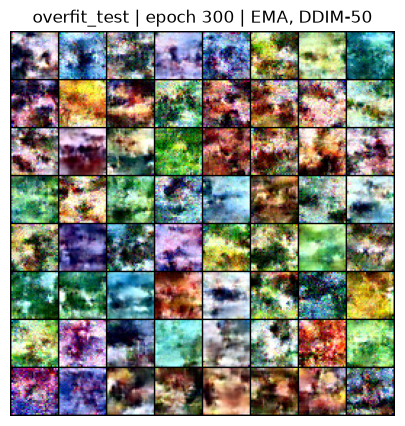

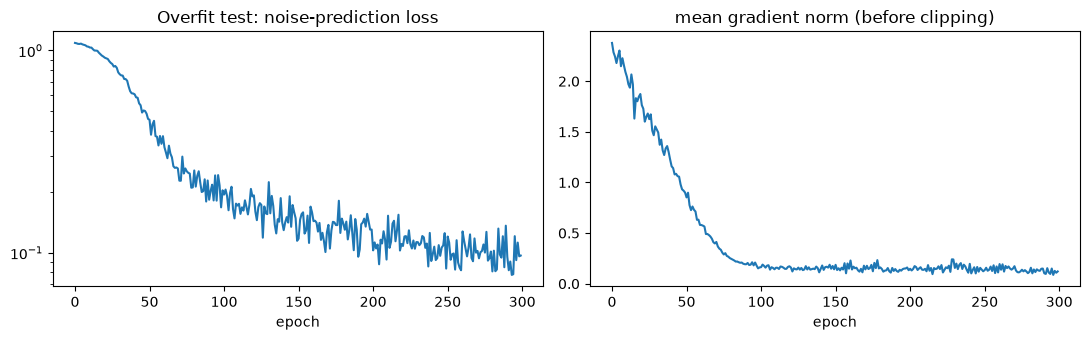

First-epoch loss: 1.089 -> last-epoch loss: 0.097


In [15]:
tiny_loader = DataLoader(Subset(train_set, list(range(64))), batch_size=64, shuffle=True, drop_last=True)

hist_tiny = train_ddpm("overfit_test", "cosine", use_attention=True, epochs=300, loader=tiny_loader,
                       log_every=10**9, save_every=10**9, print_every=100, resume=False)
plot_history(hist_tiny, "Overfit test:")
print(f"First-epoch loss: {hist_tiny['loss'][0]:.3f} -> last-epoch loss: {hist_tiny['loss'][-1]:.3f}")

**What a pass looks like:** the first-epoch loss is close to 1.0 and the curve drops clearly and quickly. The grid at the end (from only 300 steps) will be crude, but should show smooth colour blobs, not static or NaNs.

**If it fails:**
| Symptom | Likely cause |
|---|---|
| Loss stuck near 1.0 | LR too low/warmup too long, `t` not reaching the model, or noise target mismatched with `x_t` |
| NaN loss | LR too high, missing gradient clipping, `alpha_bar` hitting 0 in the schedule |
| Crash on shapes | skip-connection channel mismatch (Step 10) |

## Step 13: Full training run (primary configuration)
**Objective:** train the main model: **cosine schedule + self-attention**, on the 45,000 training images, with EMA, a checkpoint every epoch, and a fixed-seed sample grid every 5 epochs, for a fixed wall-clock budget (`TRAIN_MINUTES`).

**Time budget:** training stops after the first epoch that finishes past `TRAIN_MINUTES`. Watch the printed seconds per epoch: if one epoch takes more than about 4 minutes, interrupt, set `BASE_CH = 32` in Step 1 and restart. Report the number of epochs you actually completed. Fewer epochs than the paper means a worse FID, and that is expected.

[cosine_attn] schedule=cosine | attention=True | params=2.33M | epochs 0->1000


epoch   1/1000 | loss 0.3554 | grad norm 0.39 | 368s


epoch   2/1000 | loss 0.1106 | grad norm 0.06 | 345s


epoch   3/1000 | loss 0.0900 | grad norm 0.05 | 347s


epoch   4/1000 | loss 0.0818 | grad norm 0.05 | 240s


epoch   5/1000 | loss 0.0779 | grad norm 0.05 | 168s


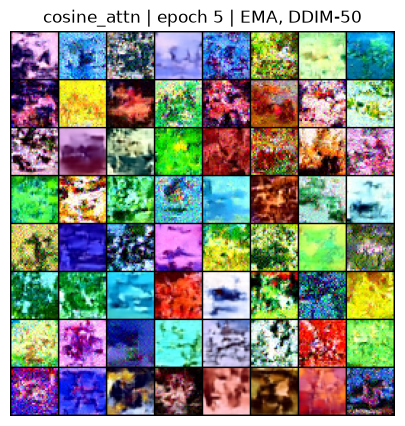

epoch   6/1000 | loss 0.0748 | grad norm 0.05 | 174s


epoch   7/1000 | loss 0.0732 | grad norm 0.05 | 175s


epoch   8/1000 | loss 0.0706 | grad norm 0.05 | 177s


epoch   9/1000 | loss 0.0694 | grad norm 0.04 | 177s


epoch  10/1000 | loss 0.0684 | grad norm 0.04 | 181s


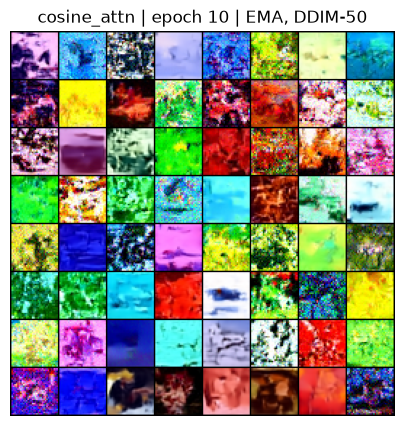

epoch  11/1000 | loss 0.0681 | grad norm 0.04 | 225s


epoch  12/1000 | loss 0.0660 | grad norm 0.04 | 272s


epoch  13/1000 | loss 0.0656 | grad norm 0.04 | 267s


epoch  14/1000 | loss 0.0658 | grad norm 0.04 | 289s


epoch  15/1000 | loss 0.0651 | grad norm 0.04 | 294s


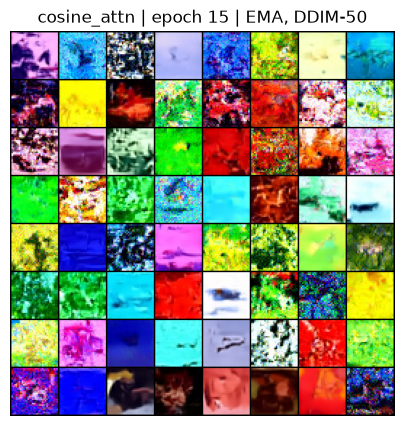

epoch  16/1000 | loss 0.0642 | grad norm 0.04 | 279s


epoch  17/1000 | loss 0.0648 | grad norm 0.04 | 278s


epoch  18/1000 | loss 0.0636 | grad norm 0.04 | 274s


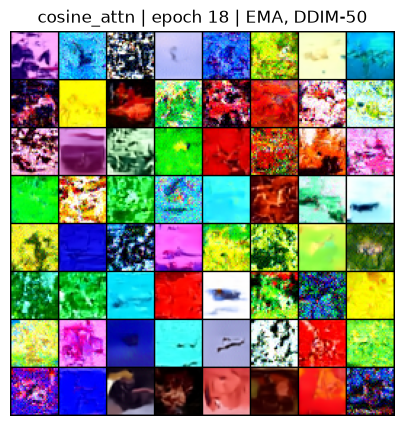

[cosine_attn] time budget of 75 min reached after 18 epochs.
Epochs completed: 18


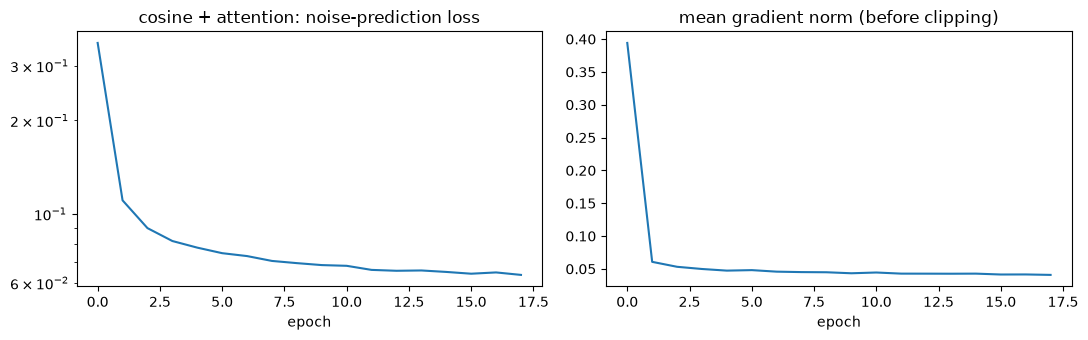

In [18]:
final_path = f"{CKPT_DIR}/cosine_attn_final.pt"
if os.path.exists(final_path):
    print("Finished checkpoint found, skipping training.")
    hist_main = torch.load(final_path, map_location="cpu")["history"]
else:
    hist_main = train_ddpm("cosine_attn", "cosine", use_attention=True, epochs=EPOCHS, loader=train_loader,
                           log_every=5, save_every=1, max_minutes=TRAIN_MINUTES)
print("Epochs completed:", len(hist_main["loss"]))
plot_history(hist_main, "cosine + attention:")

**What to look for:**
- Loss falls fast in the first few epochs, then flattens slowly. Flat is normal.
- Sample grids at epochs 10, 20, ...: blurry colour blobs first, then object-like shapes and textures. Grids are saved to `diffusion_project/samples/`.
- Gradient norm: stable, no repeated spikes.

**Debugging checklist:**
| Problem | Fix |
|---|---|
| Loss spikes/NaN | lower `LR` (1e-4), keep clipping, confirm `AMP` scaler is active |
| Samples are washed out / grey-brown | check [-1,1] scaling; sample from **EMA**, not raw, weights |
| Samples saturated/neon | make sure `x0` clipping is present in the samplers |
| Out of memory | `BATCH_SIZE=64` or `BASE_CH=32` |
| Samples look fine early then worse | EMA decay too slow for short runs (lower `EMA_DECAY` to 0.999) |

# Phase 5: Sampling
## Step 14: DDPM ancestral sampler
**Objective:** run the full 1000-step reverse process with the trained model and time it. Compare raw and EMA weights from the same starting noise.

DDPM (1000 steps, 64 images): 43s


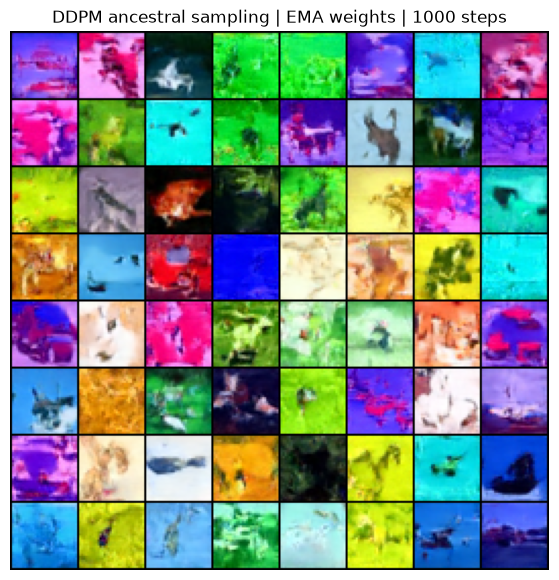

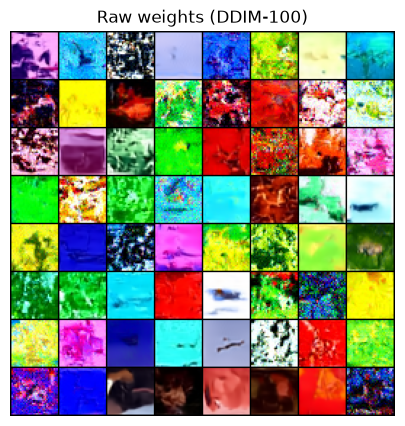

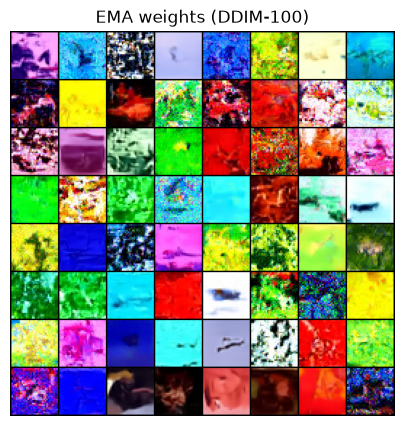

In [19]:
main = load_run("cosine_attn")

t0 = time.time()
imgs_ddpm = ddpm_sample(main["ema"], main["sched"], 64, generator=fixed_generator())
print(f"DDPM (1000 steps, 64 images): {time.time()-t0:.0f}s")
show_grid(imgs_ddpm, "DDPM ancestral sampling | EMA weights | 1000 steps")

# Raw vs EMA from identical starting noise (quick DDIM-100 so the cell is fast)
imgs_raw = ddim_sample(main["raw"], main["sched"], 64, steps=100, generator=fixed_generator())
imgs_ema = ddim_sample(main["ema"], main["sched"], 64, steps=100, generator=fixed_generator())
show_grid(imgs_raw, "Raw weights (DDIM-100)", figsize=(5, 5))
show_grid(imgs_ema, "EMA weights (DDIM-100)", figsize=(5, 5))

**Validation:** images are in a sensible colour range, and are not all identical (diversity). EMA samples are usually cleaner than raw samples; judge this by eye here and with FID in Step 16.

## Step 15: DDIM sampler (speed vs quality)
**Objective:** same trained model, fewer steps. DDIM with eta=0 is deterministic: the same starting noise always gives the same image, which is why different step counts give *related* images.

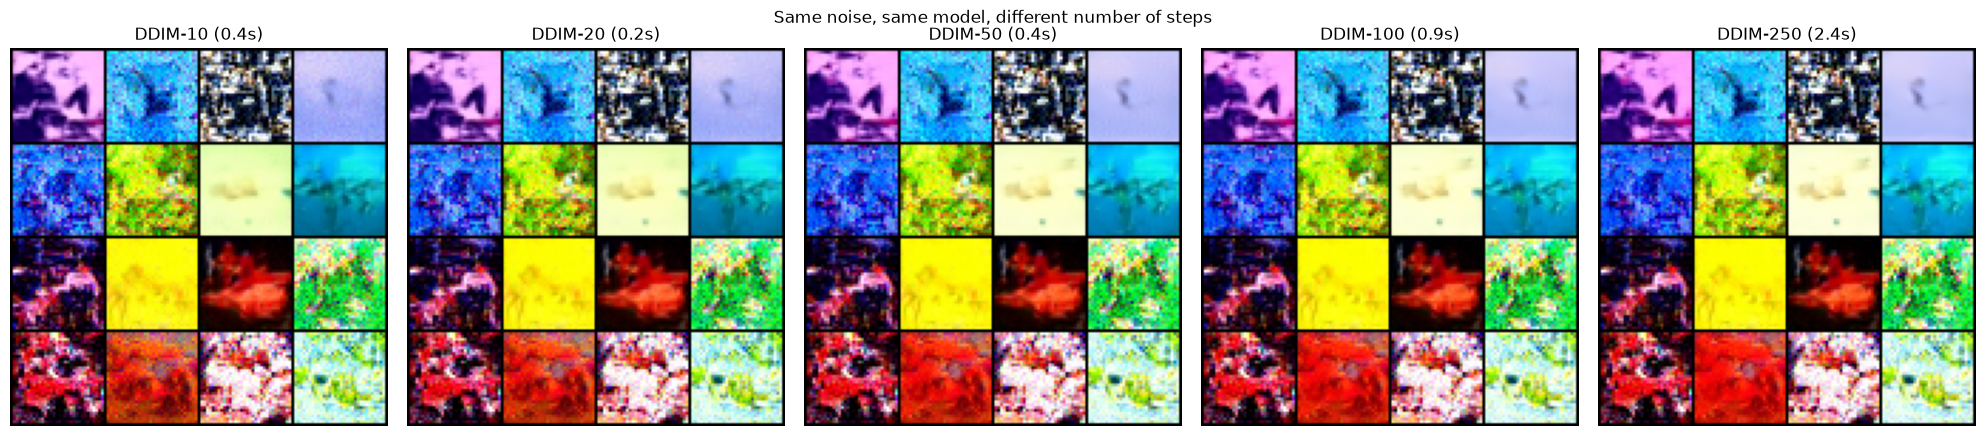

In [20]:
step_options = [10, 20, 50, 100, 250]
fig, axes = plt.subplots(1, len(step_options), figsize=(4 * len(step_options), 4.4))
for ax, steps in zip(axes, step_options):
    t0 = time.time()
    imgs = ddim_sample(main["ema"], main["sched"], 16, steps=steps, generator=fixed_generator())
    sec = time.time() - t0
    ax.imshow(vutils.make_grid(to_01(imgs.cpu()), nrow=4, padding=1).permute(1, 2, 0))
    ax.axis("off"); ax.set_title(f"DDIM-{steps} ({sec:.1f}s)")
plt.suptitle("Same noise, same model, different number of steps"); plt.tight_layout(); plt.show()

**What to look for:** very few steps (10) look blurry or oversmoothed; quality improves quickly and then saturates. The question for Step 16 is *where it saturates*, and how that compares with the 1000-step DDPM.

# Phase 6: Evaluation and comparison
## Step 16: FID and Inception Score
**Objective:** quantify sample quality.
- **FID** (lower is better): distance between Inception-feature statistics of real and generated images. Our primary metric.
- **IS** (higher is better): secondary; known to be less reliable than FID.
- **Precision / Recall:** precision = realism of samples, recall = coverage of the data distribution (diagnoses blurriness vs mode collapse).

**Fair-comparison rules (important for honest reporting):**
1. Every model is evaluated with the **same number of samples** (`N_FID`) against the **same hold-out set**.
2. Our absolute FID will be higher than published values because we use only 2,500 samples (FID is biased upward for small samples), a smaller model and shorter training. Only *relative* comparisons inside this notebook are meaningful.

In [21]:
def generate_to_dir(sample_fn, out_dir, n=N_FID, batch=250, seed=SEED):
    # sample_fn(batch_size, generator) -> images in [-1,1]; saves n PNGs to out_dir
    if os.path.exists(out_dir):
        shutil.rmtree(out_dir)
    os.makedirs(out_dir)
    gen = fixed_generator(seed)
    done = 0
    with tqdm(total=n, desc=os.path.basename(out_dir), leave=False) as bar:
        while done < n:
            b = min(batch, n - done)
            imgs = sample_fn(b, gen)
            for i in range(b):
                vutils.save_image(to_01(imgs[i]), f"{out_dir}/{done + i:05d}.png")
            done += b; bar.update(b)

def evaluate_dir(gen_dir):
    m = torch_fidelity.calculate_metrics(input1=gen_dir, input2=REAL_DIR, cuda=AMP,
                                         fid=True, isc=True, prc=True, verbose=False,
                                         input2_cache_name=f"holdout_{N_HOLDOUT}")   # real-image features computed once
    return {"FID": m["frechet_inception_distance"], "IS": m["inception_score_mean"],
            "Precision": m.get("precision"), "Recall": m.get("recall")}

results = []      # one row per evaluated (model, sampler)
gen_dirs = {}     # label -> folder with generated PNGs (used for side-by-side grids in Step 20)

def run_eval(label, model_name, sampler_name, nfe, sample_fn):
    out_dir = f"{FID_DIR}/{label}"
    t0 = time.time()
    generate_to_dir(sample_fn, out_dir)
    gen_time = time.time() - t0
    metrics = evaluate_dir(out_dir)
    results.append({"label": label, "model": model_name, "sampler": sampler_name, "NFE": nfe,
                    **metrics, "gen_time_s": round(gen_time)})
    gen_dirs[label] = out_dir
    print(f"{label:28s} FID={metrics['FID']:.2f} | IS={metrics['IS']:.2f} | gen time {gen_time:.0f}s")

RUN_FLOOR = False    # costs one extra FID evaluation; set True if you have spare time
if RUN_FLOOR:
    # Sanity check: FID of real hold-out vs *another* slice of real images should be small.
    # This tells you the "floor" you can expect with N_FID samples.
    floor_dir = f"{FID_DIR}/real_floor"
    if os.path.exists(floor_dir): shutil.rmtree(floor_dir)
    os.makedirs(floor_dir)
    for k, i in enumerate(tqdm(train_idx[:N_FID], desc="real floor", leave=False)):
        vutils.save_image(to_01(cifar_train_plain[i][0]), f"{floor_dir}/{k:05d}.png")
    floor = evaluate_dir(floor_dir)
    print(f"Real-vs-real FID floor with {N_FID} samples: {floor['FID']:.2f}  (the best any generator could do here)")

In [22]:
# ----- Main model: raw vs EMA, and DDIM step sweep -----
main = load_run("cosine_attn")
run_eval("cosine_attn_raw_DDIM50", "cosine_attn (raw)", "DDIM", 50,
         lambda b, g: ddim_sample(main["raw"], main["sched"], b, steps=50, generator=g))

for steps in [10, 20, 50, 100]:
    run_eval(f"cosine_attn_EMA_DDIM{steps}", "cosine_attn (EMA)", "DDIM", steps,
             lambda b, g, s=steps: ddim_sample(main["ema"], main["sched"], b, steps=s, generator=g))

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /Users/sundharamurali/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /Users/sundharamurali/.cache/torch/hub/checkpoints/vgg16-397923af.pth


cosine_attn_raw_DDIM50       FID=163.78 | IS=4.76 | gen time 90s


cosine_attn_EMA_DDIM10       FID=177.09 | IS=4.51 | gen time 25s


cosine_attn_EMA_DDIM20       FID=165.27 | IS=4.82 | gen time 72s


cosine_attn_EMA_DDIM50       FID=166.92 | IS=4.75 | gen time 161s


cosine_attn_EMA_DDIM100      FID=168.92 | IS=4.69 | gen time 344s


,model,sampler,NFE,FID,IS,Precision,Recall,gen_time_s
0,cosine_attn (raw),DDIM,50,163.775,4.764,0.435,0.060,90
1,cosine_attn (EMA),DDIM,10,177.089,4.511,0.349,0.028,25
2,cosine_attn (EMA),DDIM,20,165.266,4.819,0.405,0.043,72
3,cosine_attn (EMA),DDIM,50,166.923,4.752,0.416,0.074,161
4,cosine_attn (EMA),DDIM,100,168.919,4.692,0.414,0.068,344


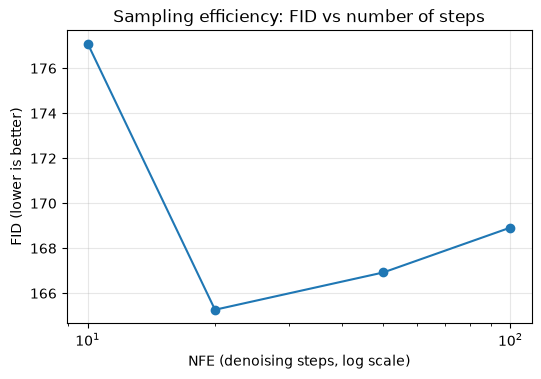

In [23]:
# ----- Full DDPM (1000 steps). This is the slow one: 1000 forward passes per batch. -----
# Set to False to skip, or lower N_FID in Step 1 for a quicker run (compare only at equal N_FID!).
RUN_DDPM_FID = False   # 1000-step DDPM over thousands of images is too slow for a 3 hour laptop budget
if RUN_DDPM_FID:
    run_eval("cosine_attn_EMA_DDPM1000", "cosine_attn (EMA)", "DDPM", 1000,
             lambda b, g: ddpm_sample(main["ema"], main["sched"], b, generator=g))

results_df = pd.DataFrame(results)
display(results_df.drop(columns="label").round(3))

# FID vs NFE (number of function evaluations)
sub = results_df[results_df["model"] == "cosine_attn (EMA)"].sort_values("NFE")
plt.figure(figsize=(6, 3.8))
plt.plot(sub["NFE"], sub["FID"], marker="o"); plt.xscale("log")
plt.xlabel("NFE (denoising steps, log scale)"); plt.ylabel("FID (lower is better)")
plt.title("Sampling efficiency: FID vs number of steps"); plt.grid(alpha=0.3); plt.show()

**How to read the results (without over-claiming):**
- **Raw vs EMA:** if EMA FID is lower, that's the benefit of weight averaging.
- **FID vs NFE:** find the smallest step count whose FID is close to the 1000-step DDPM. The ratio of steps is your DDIM speed-up. Report what *you* measure; it may differ from the 10-20x seen in the literature.
- **Real-vs-real floor:** the best case for `N_FID` samples. Your generator's FID cannot meaningfully go below it.
- With a single seed and 5,000 samples, small FID differences (about 1-2 points) may be noise. Say so in the report.

## Step 17: Ablations
**Objective:** isolate what each design choice contributes. We train three more models with **identical settings** (same epochs, seed, data, LR) and change one thing at a time:

| Run | Schedule | Attention |
|---|---|---|
| `cosine_attn` (Step 13) | cosine | yes (primary) |
| `linear_attn` | linear | yes |
| `cosine_noattn` | cosine | no |
| `linear_noattn` | linear | no (the "internal baseline" from the brief) |

**Compute warning (Mac version):** `RUN_ABLATIONS` is `False` by default; each ablation is a full extra training run at the same epoch count as the main run. If you skip it, state that in the report instead of claiming ablation results. This is 3 more full training runs. For equal-budget fairness, all runs must use the same `EPOCHS`. If time is short, reduce `EPOCHS` in Step 1 and retrain *all four* with the lower number. Each run resumes safely if Colab disconnects, and completed runs are skipped.

In [24]:
ablation_cfgs = [("linear_attn", "linear", True),
                 ("cosine_noattn", "cosine", False),
                 ("linear_noattn", "linear", False)]

RUN_ABLATIONS = False   # each ablation is a full extra training run
ablation_hist = {}
for run_name, sched_name, attn in (ablation_cfgs if RUN_ABLATIONS else []):
    if not os.path.exists(f"{CKPT_DIR}/{run_name}_final.pt"):
        ablation_hist[run_name] = train_ddpm(run_name, sched_name, attn, len(hist_main["loss"]), train_loader,
                                             log_every=5, save_every=1)
    r = load_run(run_name)
    run_eval(f"{run_name}_EMA_DDIM100", f"{run_name} (EMA)", "DDIM", 100,
             lambda b, g, r=r: ddim_sample(r["ema"], r["sched"], b, steps=100, generator=g))

In [25]:
results_df = pd.DataFrame(results)
abl_names = ["cosine_attn (EMA)", "linear_attn (EMA)", "cosine_noattn (EMA)", "linear_noattn (EMA)"]
abl = results_df[(results_df["model"].isin(abl_names)) & (results_df["sampler"] == "DDIM") & (results_df["NFE"] == 100)]
display(abl[["model", "FID", "IS", "Precision", "Recall"]].sort_values("FID").round(3))

,model,FID,IS,Precision,Recall
4,cosine_attn (EMA),168.919,4.692,0.414,0.068


**Interpretation guide:** compare `cosine` vs `linear` at fixed attention (schedule effect) and `attn` vs `noattn` at fixed schedule (attention effect). The literature suggests cosine and attention help, but at 32x32 with short training the effect can be small, and one seed cannot separate a small effect from noise. Report the table as measured and state that limitation.

## Step 18: Baselines (AE, VAE, DCGAN)
**Objective:** show *why* diffusion is worth the effort by comparing against earlier generative approaches on the same data and metrics.

- **AE** (autoencoder): learns to compress and reconstruct. It was never trained to generate, so we sample latent codes from a Gaussian fitted to the training latents. Expect poor samples (this is the lower bound).
- **VAE:** same architecture, but trained with a KL term so the latent space is a standard normal and can be sampled directly. Expect blurry samples.
- **DCGAN:** generator vs discriminator. Often sharp but unstable; we log both losses so you can discuss stability.

All three train for `BASELINE_EPOCHS`. We record wall-clock time so you can state the compute used. Be explicit in the report about how "equal compute" was defined; epochs and seconds are not the same thing across architectures.

In [26]:
class ConvAE(nn.Module):
    # One class serves both AE and VAE; `variational` switches on the mean/log-variance heads
    def __init__(self, latent_dim=128, variational=False):
        super().__init__()
        self.variational, self.latent_dim = variational, latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.ReLU(),                                   # 16x16
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),            # 8x8
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.ReLU(),           # 4x4
            nn.Flatten())
        self.fc_enc = nn.Linear(256 * 4 * 4, latent_dim * (2 if variational else 1))
        self.fc_dec = nn.Linear(latent_dim, 256 * 4 * 4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),  # 8x8
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),    # 16x16
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh())                          # 32x32 in [-1,1]

    def encode(self, x):
        h = self.fc_enc(self.encoder(x))
        if self.variational:
            mu, logvar = h.chunk(2, dim=1)
            return mu, logvar
        return h, None

    def decode(self, z):
        return self.decoder(self.fc_dec(z).view(-1, 256, 4, 4))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu) if self.variational else mu
        return self.decode(z), mu, logvar

def train_ae(variational, epochs=BASELINE_EPOCHS):
    torch.manual_seed(SEED)
    model = ConvAE(variational=variational).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    losses, t0 = [], time.time()
    for epoch in range(epochs):
        model.train(); ep = []
        for x, _ in train_loader:
            x = x.to(device)
            recon, mu, logvar = model(x)
            loss = F.mse_loss(recon, x, reduction="sum") / x.size(0)                 # reconstruction error per image
            if variational:
                loss = loss + (-0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp()) / x.size(0))   # KL term
            opt.zero_grad(); loss.backward(); opt.step(); ep.append(loss.item())
        losses.append(float(np.mean(ep)))
        if (epoch + 1) % 10 == 0:
            print(f"{'VAE' if variational else 'AE'} epoch {epoch+1}/{epochs} | loss {losses[-1]:.1f}")
    return model.eval(), losses, time.time() - t0

# ---------- DCGAN ----------
class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, 256, 4, 1, 0), nn.BatchNorm2d(256), nn.ReLU(),   # 4x4
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),     # 8x8
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),       # 16x16
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh())                             # 32x32
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.LeakyReLU(0.2),                              # 16x16
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),       # 8x8
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2),      # 4x4
            nn.Conv2d(256, 1, 4, 1, 0))                                                # 1 logit
    def forward(self, x):
        return self.net(x).view(-1)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)

def train_dcgan(epochs=BASELINE_EPOCHS, z_dim=100):
    torch.manual_seed(SEED)
    G, D = Generator(z_dim).to(device), Discriminator().to(device)
    G.apply(init_weights); D.apply(init_weights)
    optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    hist, t0 = {"D": [], "G": []}, time.time()
    for epoch in range(epochs):
        dl, gl = [], []
        for x, _ in train_loader:
            x = x.to(device); b = x.size(0)
            z = torch.randn(b, z_dim, 1, 1, device=device)
            fake = G(z)
            # Discriminator: real -> 1, fake -> 0
            lossD = bce(D(x), torch.ones(b, device=device)) + bce(D(fake.detach()), torch.zeros(b, device=device))
            optD.zero_grad(); lossD.backward(); optD.step()
            # Generator: try to make D say "real"
            lossG = bce(D(fake), torch.ones(b, device=device))
            optG.zero_grad(); lossG.backward(); optG.step()
            dl.append(lossD.item()); gl.append(lossG.item())
        hist["D"].append(float(np.mean(dl))); hist["G"].append(float(np.mean(gl)))
        if (epoch + 1) % 10 == 0:
            print(f"DCGAN epoch {epoch+1}/{epochs} | D {hist['D'][-1]:.3f} | G {hist['G'][-1]:.3f}")
    return G.eval(), hist, time.time() - t0

In [28]:
ae_model,  ae_hist,  ae_time  = train_ae(variational=False)
vae_model, vae_hist, vae_time = train_ae(variational=True)
G, gan_hist, gan_time = train_dcgan()
print(f"Training time (s): AE={ae_time:.0f} | VAE={vae_time:.0f} | DCGAN={gan_time:.0f}")

AE epoch 10/10 | loss 59.9
VAE epoch 10/10 | loss 207.1
DCGAN epoch 10/10 | D 0.824 | G 1.948
Training time (s): AE=130 | VAE=153 | DCGAN=292


AE                           FID=162.40 | IS=2.67 | gen time 1s


VAE                          FID=194.11 | IS=2.45 | gen time 1s


DCGAN                        FID=126.79 | IS=3.72 | gen time 1s


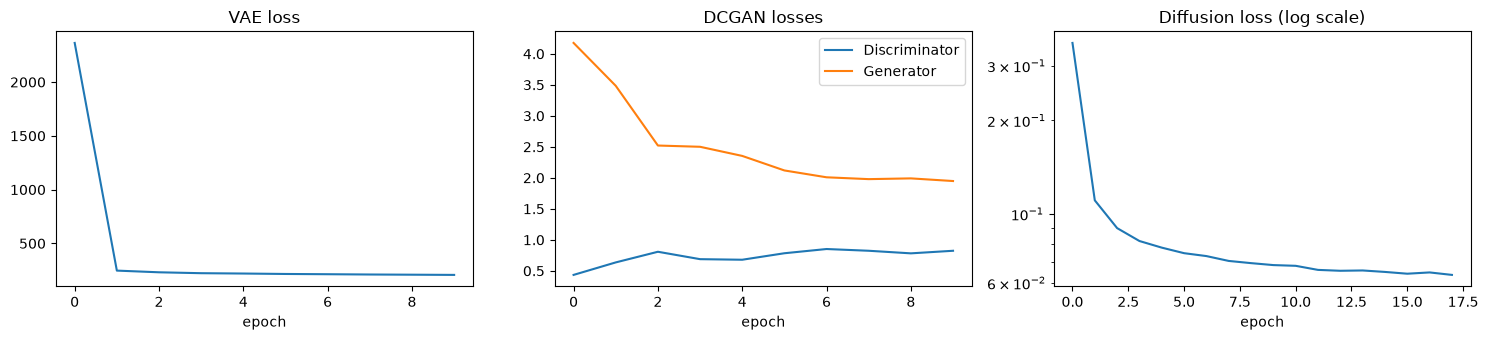

In [29]:
# ---------- Sampling functions for the baselines ----------
with torch.no_grad():
    # For the plain AE the latent space is unregularised, so we fit a per-dimension Gaussian to the training latents
    lat = torch.cat([ae_model.encode(x.to(device))[0] for x, _ in train_loader])
    ae_mu, ae_std = lat.mean(0), lat.std(0)

@torch.no_grad()
def ae_sample(b, gen):
    z = ae_mu + ae_std * torch.randn((b, ae_model.latent_dim), generator=gen).to(device)
    return ae_model.decode(z)

@torch.no_grad()
def vae_sample(b, gen):
    return vae_model.decode(torch.randn((b, vae_model.latent_dim), generator=gen).to(device))

@torch.no_grad()
def gan_sample(b, gen):
    return G(torch.randn((b, 100, 1, 1), generator=gen).to(device))

for name, fn in [("AE", ae_sample), ("VAE", vae_sample), ("DCGAN", gan_sample)]:
    run_eval(name, name, "single pass", 1, fn)

# ---------- Training-stability comparison ----------
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(vae_hist); ax[0].set_title("VAE loss"); ax[0].set_xlabel("epoch")
ax[1].plot(gan_hist["D"], label="Discriminator"); ax[1].plot(gan_hist["G"], label="Generator")
ax[1].set_title("DCGAN losses"); ax[1].legend(); ax[1].set_xlabel("epoch")
ax[2].plot(hist_main["loss"]); ax[2].set_yscale("log"); ax[2].set_title("Diffusion loss (log scale)"); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()

**What to look for (report what you actually see):**
- AE/VAE samples are typically blurry; the AE with a fitted Gaussian will usually be worst.
- DCGAN can have competitive FID but check the grid for repeated or similar-looking images (mode collapse) and look at the Precision/Recall columns: low recall with decent precision suggests collapse.
- GAN losses oscillate against each other (adversarial game) whereas the diffusion loss is a plain regression curve. That is the "training stability" argument, which is only a qualitative claim from one run each.

# Phase 7: Extensions and wrap-up
## Step 19 (optional): Classifier-free guidance
**Objective:** make the model class-conditional using CIFAR-10 labels. During training the label is randomly hidden for 10% of examples (`P_UNCOND`), so one network learns both conditional and unconditional denoising. At sampling time we blend the two predictions:

`eps = (1 + w) * eps_conditional - w * eps_unconditional`

Larger `w` gives more class-consistent but less diverse samples. This is **another full training run**; skip it if you're short on time. (CelebA 64x64 is the other optional extension; it needs a manual dataset download and roughly 4x the compute, so it isn't included here. The pipeline above is resolution-agnostic apart from `IMG_SIZE` and the attention resolutions.)

In [30]:
RUN_CFG = False        # set True to run the optional extension
if RUN_CFG:
    hist_cfg = train_ddpm("cfg_cosine_attn", "cosine", use_attention=True, epochs=EPOCHS, loader=train_loader,
                          class_cond=True, log_every=EPOCHS, save_every=5)
    cfg_run = load_run("cfg_cosine_attn")

    # Grid: one column per class (airplane ... truck), rows are different samples
    y_grid = torch.arange(10, device=device).repeat(8)
    for w in [0.0, 1.0, 3.0]:
        imgs = ddim_sample(cfg_run["ema"], cfg_run["sched"], 80, steps=100, generator=fixed_generator(),
                           y=y_grid, guidance_w=w)
        show_grid(imgs, f"Guidance w={w} (columns = {', '.join(classes)})", nrow=10, figsize=(10, 8))

    # FID / IS / Precision / Recall at each guidance strength
    for w in [0.0, 1.0, 3.0]:
        run_eval(f"cfg_w{w}", f"cfg cosine_attn w={w}", "DDIM", 100,
                 lambda b, g, w=w: ddim_sample(cfg_run["ema"], cfg_run["sched"], b, steps=100, generator=g,
                                               y=(torch.arange(b, device=device) % 10), guidance_w=w))

**What to look for:** with higher `w`, samples should look more clearly like their class, while diversity (Recall) typically drops. Note that FID may *worsen* at high `w` even though the images look more class-consistent, because FID rewards matching the full data distribution. This precision-vs-diversity trade-off is the key point to explain.

## Step 20: Final comparison and documentation
**Objective:** assemble one comparison table, side-by-side sample grids, save the results to Drive, and write the report.

,model,sampler,NFE,FID,IS,Precision,Recall,gen_time_s
0,DCGAN,single pass,1,126.793,3.725,0.848,0.006,1
1,AE,single pass,1,162.400,2.672,0.682,0.000,1
2,cosine_attn (raw),DDIM,50,163.775,4.764,0.435,0.060,90
3,cosine_attn (EMA),DDIM,20,165.266,4.819,0.405,0.043,72
4,cosine_attn (EMA),DDIM,50,166.923,4.752,0.416,0.074,161
5,cosine_attn (EMA),DDIM,100,168.919,4.692,0.414,0.068,344
6,cosine_attn (EMA),DDIM,10,177.089,4.511,0.349,0.028,25
7,VAE,single pass,1,194.107,2.447,0.993,0.000,1


Saved: ./diffusion_project/results.csv


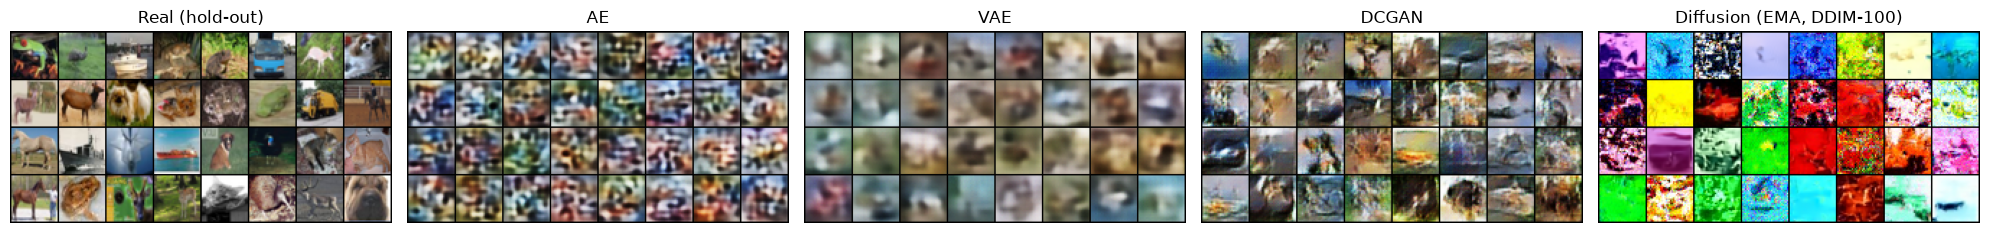

In [31]:
final_df = pd.DataFrame(results).drop(columns="label").sort_values("FID").reset_index(drop=True)
display(final_df.round(3))
final_df.to_csv(f"{PROJECT_DIR}/results.csv", index=False)
print("Saved:", f"{PROJECT_DIR}/results.csv")

# ---------- Side-by-side sample grids ----------
def load_first_n(folder, n=32):
    files = sorted(os.listdir(folder))[:n]
    return torch.stack([transforms.ToTensor()(Image.open(f"{folder}/{f}").convert("RGB")) for f in files])

panels = [("Real (hold-out)", REAL_DIR), ("AE", gen_dirs.get("AE")), ("VAE", gen_dirs.get("VAE")),
          ("DCGAN", gen_dirs.get("DCGAN")), ("Diffusion (EMA, DDIM-100)", gen_dirs.get("cosine_attn_EMA_DDIM100"))]
panels = [(n, d) for n, d in panels if d is not None]
fig, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 4.4))
for ax, (name, folder) in zip(np.atleast_1d(axes), panels):
    ax.imshow(vutils.make_grid(load_first_n(folder), nrow=8, padding=1).permute(1, 2, 0))
    ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()
fig.savefig(f"{SAMPLE_DIR}/side_by_side.png", dpi=150, bbox_inches="tight")

### Report template (fill in with your own measured numbers)

**1. Problem.** Can a diffusion model, built from its core components rather than a library pipeline, produce higher-fidelity and more stable-to-train image samples than AE, VAE and DCGAN baselines on CIFAR-10?

**2. Method.** Forward noising with linear and cosine schedules (T=1000); time-conditioned U-Net (`BASE_CH`=__, attention at 16x16/8x8, __M parameters); noise-prediction MSE objective; AdamW/Adam, lr __, batch __, __ epochs, AMP, gradient clipping, EMA decay __; DDPM ancestral and DDIM samplers.

**3. Evaluation protocol.** FID, IS, Precision/Recall using `torch-fidelity` on __ generated images vs a __-image hold-out set; real-vs-real FID floor = __.

**4. Results.** *(paste table from above)*
- Best configuration: __ (FID __)
- EMA vs raw: __
- DDIM vs DDPM: DDIM-__ reaches FID within __ of DDPM-1000 using __x fewer steps
- Schedule effect (cosine vs linear): __; attention effect: __
- Diffusion vs baselines: __

**5. Training stability.** Diffusion loss curve: __. DCGAN loss behaviour: __. Any NaNs/spikes encountered and how they were fixed: __.

**6. Limitations (be honest, since the brief asks for it).**
- The published DDPM reports FID of about 3.17 with a much larger model, much longer training and 50,000-sample FID. Our FID is __; the gap is expected from (a) model size, (b) training length, (c) smaller FID sample, (d) single seed.
- Single run per configuration; differences within about 1-2 FID points should not be treated as significant.
- Baselines are simple architectures with a short schedule; stronger tuned baselines would narrow the gap.

**7. Business relevance.** Synthetic data for rare classes, privacy-preserving data sharing, design tooling, edge-case simulation, restoration (see brief). Latent diffusion (Stable Diffusion's approach) is the natural next step for scaling to higher resolution.

**8. Possible next steps.** Latent diffusion in a VAE latent space, longer training with `BASE_CH`=128, multiple seeds with confidence intervals, CelebA 64x64.